/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet34_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet34_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth
100%|██████████| 83.3M/83.3M [00:00<00:00, 188MB/s] 


Model saved to svm_classifier_rgb_model.pkl
Validation Classification Report:
              precision    recall  f1-score   support

         ALM       0.97      1.00      0.99       116
   M in SItu       0.83      0.89      0.86        44
          NM       1.00      0.88      0.93        40
         SSM       0.92      0.91      0.92        80

    accuracy                           0.94       280
   macro avg       0.93      0.92      0.92       280
weighted avg       0.94      0.94      0.94       280

Validation Confusion Matrix:
[[116   0   0   0]
 [  0  39   0   5]
 [  3   1  35   1]
 [  0   7   0  73]]


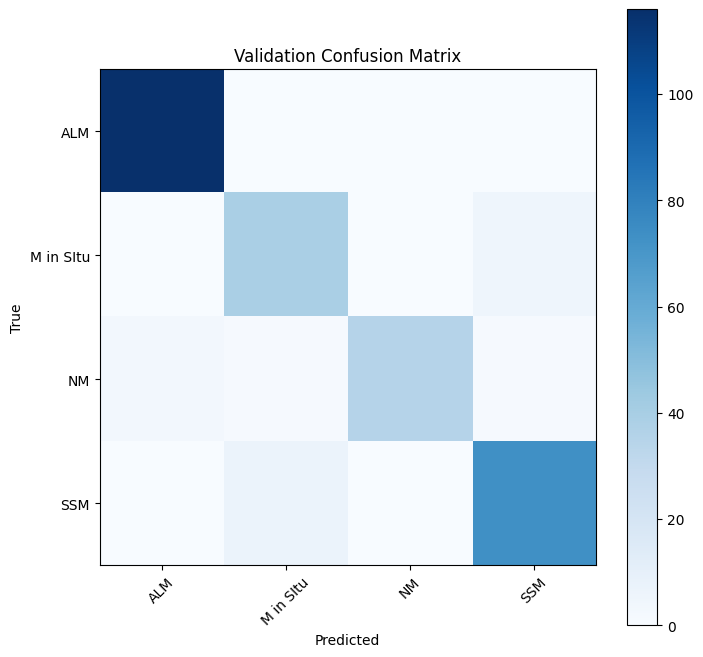

Test Classification Report:
              precision    recall  f1-score   support

         ALM       0.96      1.00      0.98        26
   M in SItu       0.90      0.79      0.84        24
          NM       1.00      0.94      0.97        18
         SSM       0.78      0.90      0.84        20

    accuracy                           0.91        88
   macro avg       0.91      0.91      0.91        88
weighted avg       0.91      0.91      0.91        88

Test Confusion Matrix:
[[26  0  0  0]
 [ 0 19  0  5]
 [ 1  0 17  0]
 [ 0  2  0 18]]


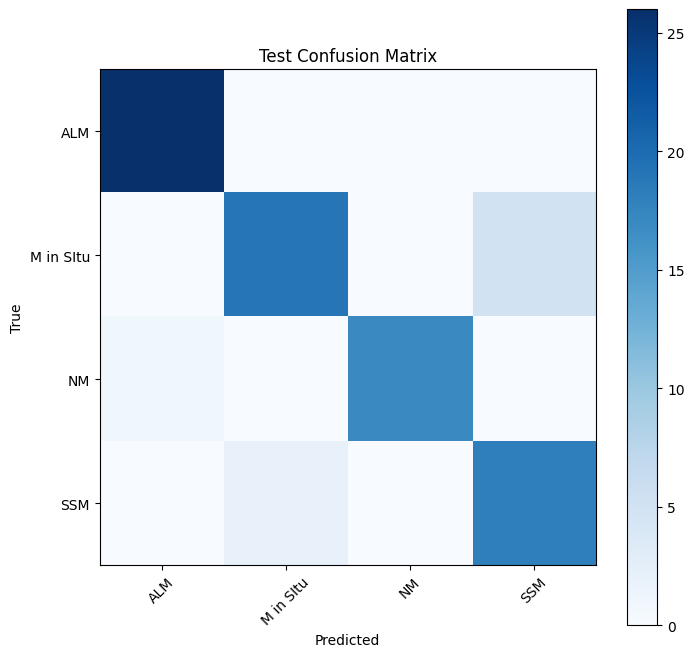

In [1]:
import torch
import torch.nn as nn
from torchvision import datasets, models, transforms
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt
import joblib
import os


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


train_dir = '/kaggle/input/train-rgb'
val_dir = '/kaggle/input/valid-rgb'
test_dir = '/kaggle/input/test-rgb'


data_transforms = transforms.Compose([
    transforms.Resize((640, 640)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])


train_dataset = datasets.ImageFolder(train_dir, transform=data_transforms)
val_dataset = datasets.ImageFolder(val_dir, transform=data_transforms)
test_dataset = datasets.ImageFolder(test_dir, transform=data_transforms)


train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=False)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)


resnet34 = models.resnet34(pretrained=True)

feature_extractor = nn.Sequential(*list(resnet34.children())[:-1]).to(device)
feature_extractor.eval()  


def extract_features(data_loader):
    features = []
    labels = []
    
    with torch.no_grad():
        for inputs, lbls in data_loader:
            inputs = inputs.to(device)
            output = feature_extractor(inputs)
            output = output.view(output.size(0), -1)  # Flatten the output
            features.append(output.cpu().numpy())
            labels.append(lbls.numpy())
    
    return np.concatenate(features), np.concatenate(labels)


train_features, train_labels = extract_features(train_loader)
val_features, val_labels = extract_features(val_loader)
test_features, test_labels = extract_features(test_loader)


scaler = StandardScaler()
train_features = scaler.fit_transform(train_features)
val_features = scaler.transform(val_features)
test_features = scaler.transform(test_features)


svm_classifier = SVC(kernel='linear', C=1, random_state=42)
svm_classifier.fit(train_features, train_labels)


model_save_path = 'svm_classifier_rgb_model.pkl'
joblib.dump(svm_classifier, model_save_path)
print(f"Model saved to {model_save_path}")


val_predictions = svm_classifier.predict(val_features)
test_predictions = svm_classifier.predict(test_features)


print("Validation Classification Report:")
print(classification_report(val_labels, val_predictions, target_names=val_dataset.classes))

print("Validation Confusion Matrix:")
conf_mat_val = confusion_matrix(val_labels, val_predictions)
print(conf_mat_val)


plt.figure(figsize=(8, 8))
plt.imshow(conf_mat_val, cmap='Blues')
plt.colorbar()
plt.xticks(np.arange(len(val_dataset.classes)), val_dataset.classes, rotation=45)
plt.yticks(np.arange(len(val_dataset.classes)), val_dataset.classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Validation Confusion Matrix')
plt.show()


print("Test Classification Report:")
print(classification_report(test_labels, test_predictions, target_names=test_dataset.classes))

print("Test Confusion Matrix:")
conf_mat_test = confusion_matrix(test_labels, test_predictions)
print(conf_mat_test)


plt.figure(figsize=(8, 8))
plt.imshow(conf_mat_test, cmap='Blues')
plt.colorbar()
plt.xticks(np.arange(len(test_dataset.classes)), test_dataset.classes, rotation=45)
plt.yticks(np.arange(len(test_dataset.classes)), test_dataset.classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Test Confusion Matrix')
plt.show()


/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet34_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet34_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Model saved to svm_classifier_save_model.pkl
Validation Classification Report:
              precision    recall  f1-score   support

         ALM       0.99      1.00      1.00       116
   M in Situ       0.81      0.80      0.80        44
          NM       1.00      0.97      0.99        40
         SSM       0.89      0.90      0.89        80

    accuracy                           0.94       280
   macro avg       0.92      0.92      0.92       280
weighted avg       0.94      0.94      0.94       280

Validation Confusion Matrix:
[[116   0   0   0]
 [  0  35   0   9]
 [  1   0  39   0]
 [  0   8   0  72]]


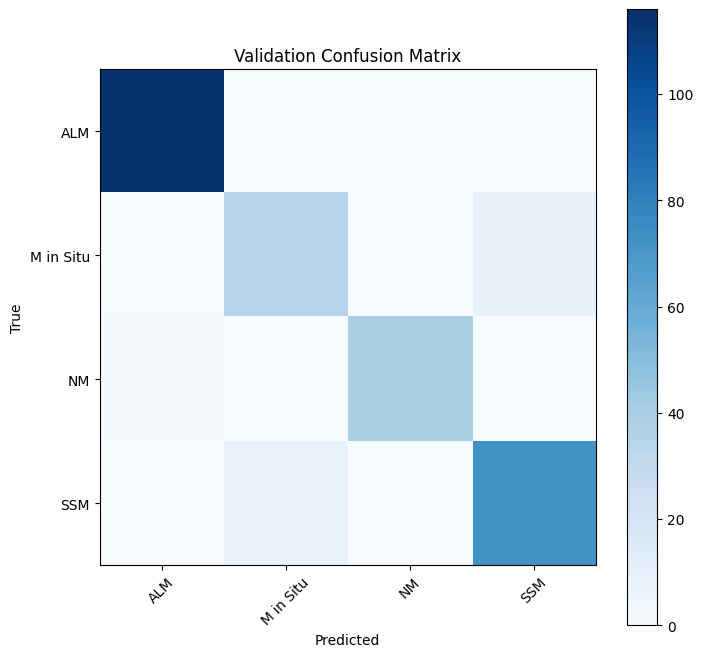

Test Classification Report:
              precision    recall  f1-score   support

         ALM       1.00      1.00      1.00        26
   M in SItu       0.92      0.92      0.92        24
          NM       1.00      1.00      1.00        18
         SSM       0.90      0.90      0.90        20

    accuracy                           0.95        88
   macro avg       0.95      0.95      0.95        88
weighted avg       0.95      0.95      0.95        88

Test Confusion Matrix:
[[26  0  0  0]
 [ 0 22  0  2]
 [ 0  0 18  0]
 [ 0  2  0 18]]


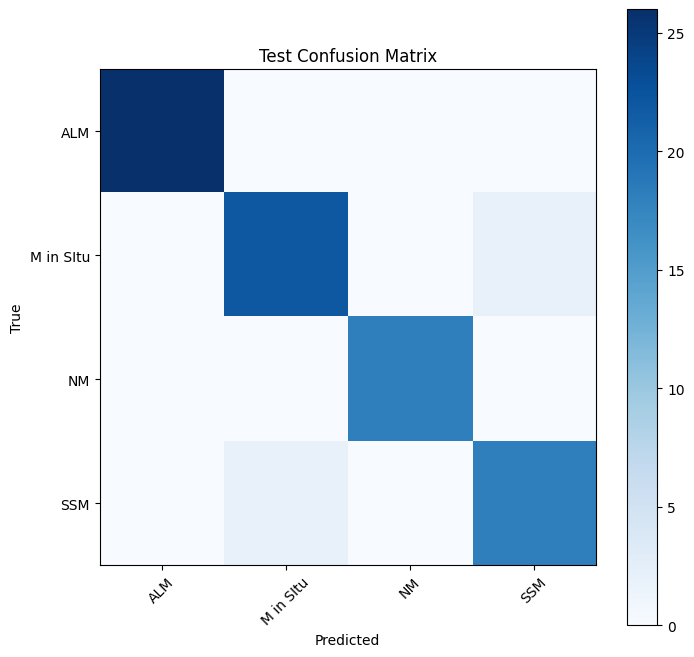

In [3]:
import torch
import torch.nn as nn
from torchvision import datasets, models, transforms
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt
import joblib
import os


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


train_dir = '/kaggle/input/train-save'
val_dir = '/kaggle/input/valid-save'
test_dir = '/kaggle/input/test-save'


data_transforms = transforms.Compose([
    transforms.Resize((640, 640)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])


train_dataset = datasets.ImageFolder(train_dir, transform=data_transforms)
val_dataset = datasets.ImageFolder(val_dir, transform=data_transforms)
test_dataset = datasets.ImageFolder(test_dir, transform=data_transforms)


train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=False)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)


resnet34 = models.resnet34(pretrained=True)

feature_extractor = nn.Sequential(*list(resnet34.children())[:-1]).to(device)
feature_extractor.eval()  

def extract_features(data_loader):
    features = []
    labels = []
    
    with torch.no_grad():
        for inputs, lbls in data_loader:
            inputs = inputs.to(device)
            output = feature_extractor(inputs)
            output = output.view(output.size(0), -1)  
            features.append(output.cpu().numpy())
            labels.append(lbls.numpy())
    
    return np.concatenate(features), np.concatenate(labels)


train_features, train_labels = extract_features(train_loader)
val_features, val_labels = extract_features(val_loader)
test_features, test_labels = extract_features(test_loader)


scaler = StandardScaler()
train_features = scaler.fit_transform(train_features)
val_features = scaler.transform(val_features)
test_features = scaler.transform(test_features)


svm_classifier = SVC(kernel='linear', C=1, random_state=42)
svm_classifier.fit(train_features, train_labels)


model_save_path = 'svm_classifier_save_model.pkl'
joblib.dump(svm_classifier, model_save_path)
print(f"Model saved to {model_save_path}")


val_predictions = svm_classifier.predict(val_features)
test_predictions = svm_classifier.predict(test_features)


print("Validation Classification Report:")
print(classification_report(val_labels, val_predictions, target_names=val_dataset.classes))

print("Validation Confusion Matrix:")
conf_mat_val = confusion_matrix(val_labels, val_predictions)
print(conf_mat_val)


plt.figure(figsize=(8, 8))
plt.imshow(conf_mat_val, cmap='Blues')
plt.colorbar()
plt.xticks(np.arange(len(val_dataset.classes)), val_dataset.classes, rotation=45)
plt.yticks(np.arange(len(val_dataset.classes)), val_dataset.classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Validation Confusion Matrix')
plt.show()


print("Test Classification Report:")
print(classification_report(test_labels, test_predictions, target_names=test_dataset.classes))

print("Test Confusion Matrix:")
conf_mat_test = confusion_matrix(test_labels, test_predictions)
print(conf_mat_test)


plt.figure(figsize=(8, 8))
plt.imshow(conf_mat_test, cmap='Blues')
plt.colorbar()
plt.xticks(np.arange(len(test_dataset.classes)), test_dataset.classes, rotation=45)
plt.yticks(np.arange(len(test_dataset.classes)), test_dataset.classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Test Confusion Matrix')
plt.show()


/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet34_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet34_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Model saved to svm_classifier_save1_model.pkl
Validation Classification Report:
              precision    recall  f1-score   support

         ALM       0.99      1.00      1.00       116
   M in Situ       0.81      0.80      0.80        44
          NM       1.00      0.97      0.99        40
         SSM       0.89      0.90      0.89        80

    accuracy                           0.94       280
   macro avg       0.92      0.92      0.92       280
weighted avg       0.94      0.94      0.94       280

Validation Confusion Matrix:
[[116   0   0   0]
 [  0  35   0   9]
 [  1   0  39   0]
 [  0   8   0  72]]


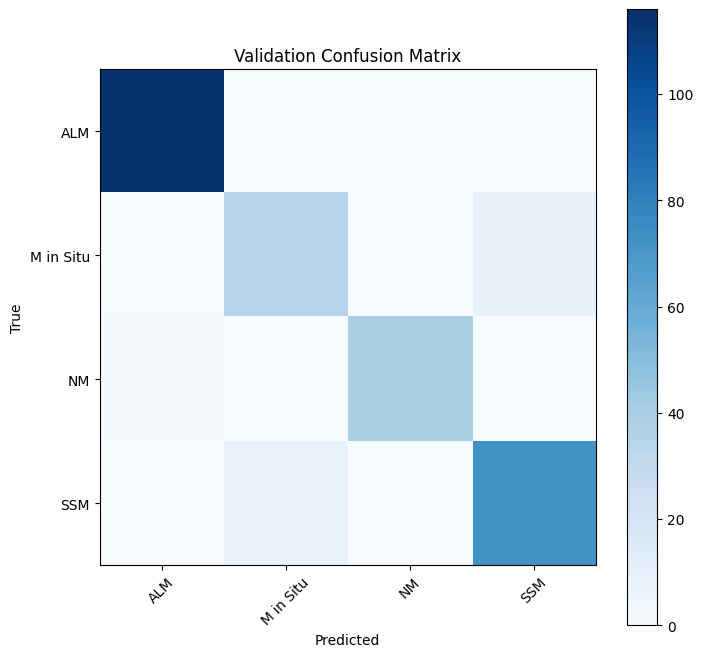

Test Classification Report:
              precision    recall  f1-score   support

         ALM       1.00      1.00      1.00        26
   M in SItu       0.92      0.92      0.92        24
          NM       1.00      1.00      1.00        18
         SSM       0.90      0.90      0.90        20

    accuracy                           0.95        88
   macro avg       0.95      0.95      0.95        88
weighted avg       0.95      0.95      0.95        88

Test Confusion Matrix:
[[26  0  0  0]
 [ 0 22  0  2]
 [ 0  0 18  0]
 [ 0  2  0 18]]


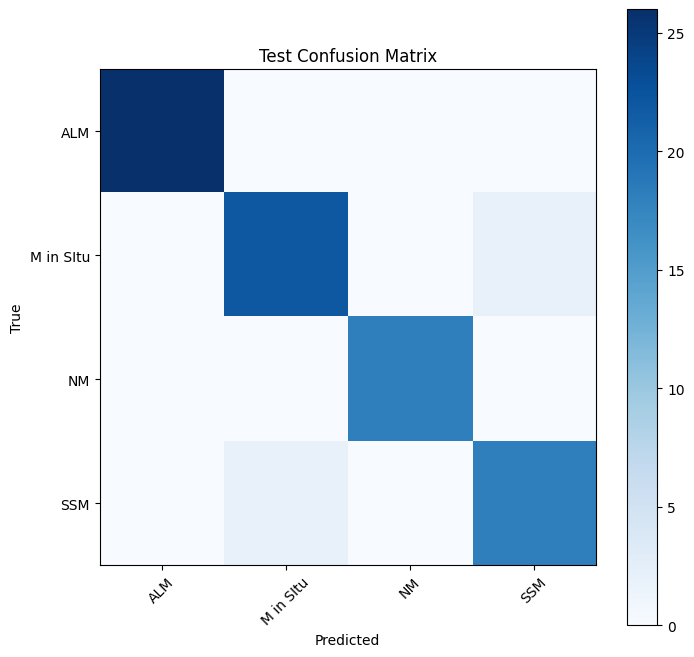

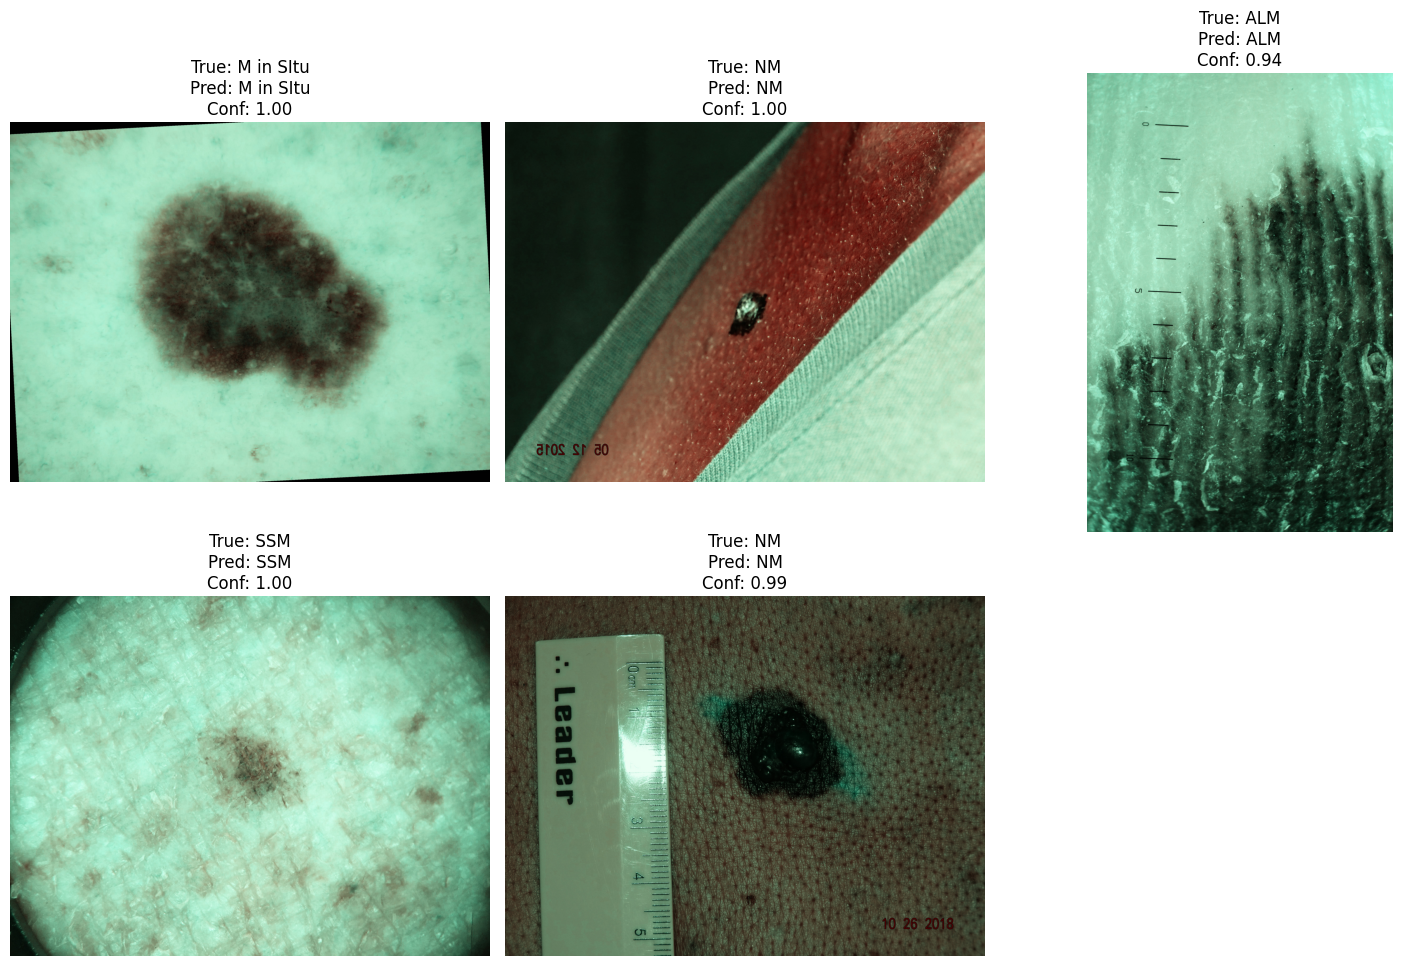

In [11]:
import torch
import torch.nn as nn
from torchvision import datasets, models, transforms
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt
import joblib
import os


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


train_dir = '/kaggle/input/train-save'
val_dir = '/kaggle/input/valid-save'
test_dir = '/kaggle/input/test-save'


data_transforms = transforms.Compose([
    transforms.Resize((640, 640)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])


train_dataset = datasets.ImageFolder(train_dir, transform=data_transforms)
val_dataset = datasets.ImageFolder(val_dir, transform=data_transforms)
test_dataset = datasets.ImageFolder(test_dir, transform=data_transforms)


train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=False)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)


resnet34 = models.resnet34(pretrained=True)

feature_extractor = nn.Sequential(*list(resnet34.children())[:-1]).to(device)
feature_extractor.eval()  # Set to evaluation mode


def extract_features(data_loader):
    features = []
    labels = []
    
    with torch.no_grad():
        for inputs, lbls in data_loader:
            inputs = inputs.to(device)
            output = feature_extractor(inputs)
            output = output.view(output.size(0), -1)  # Flatten the output
            features.append(output.cpu().numpy())
            labels.append(lbls.numpy())
    
    return np.concatenate(features), np.concatenate(labels)


train_features, train_labels = extract_features(train_loader)
val_features, val_labels = extract_features(val_loader)
test_features, test_labels = extract_features(test_loader)


scaler = StandardScaler()
train_features = scaler.fit_transform(train_features)
val_features = scaler.transform(val_features)
test_features = scaler.transform(test_features)


svm_classifier = SVC(kernel='linear', C=1, probability=True, random_state=42)
svm_classifier.fit(train_features, train_labels)


model_save_path = 'svm_classifier_save1_model.pkl'
joblib.dump(svm_classifier, model_save_path)
print(f"Model saved to {model_save_path}")


val_predictions = svm_classifier.predict(val_features)
test_predictions = svm_classifier.predict(test_features)
test_pred_proba = svm_classifier.predict_proba(test_features)


print("Validation Classification Report:")
print(classification_report(val_labels, val_predictions, target_names=val_dataset.classes))

print("Validation Confusion Matrix:")
conf_mat_val = confusion_matrix(val_labels, val_predictions)
print(conf_mat_val)


plt.figure(figsize=(8, 8))
plt.imshow(conf_mat_val, cmap='Blues')
plt.colorbar()
plt.xticks(np.arange(len(val_dataset.classes)), val_dataset.classes, rotation=45)
plt.yticks(np.arange(len(val_dataset.classes)), val_dataset.classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Validation Confusion Matrix')
plt.show()


print("Test Classification Report:")
print(classification_report(test_labels, test_predictions, target_names=test_dataset.classes))

print("Test Confusion Matrix:")
conf_mat_test = confusion_matrix(test_labels, test_predictions)
print(conf_mat_test)


plt.figure(figsize=(8, 8))
plt.imshow(conf_mat_test, cmap='Blues')
plt.colorbar()
plt.xticks(np.arange(len(test_dataset.classes)), test_dataset.classes, rotation=45)
plt.yticks(np.arange(len(test_dataset.classes)), test_dataset.classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Test Confusion Matrix')
plt.show()


loaded_svm_model = joblib.load(model_save_path)
loaded_test_predictions = loaded_svm_model.predict(test_features)
loaded_test_pred_proba = loaded_svm_model.predict_proba(test_features)


predictions_df = pd.DataFrame({
    'True Label': test_labels,
    'Predicted Label': loaded_test_predictions,
    'Confidence': np.max(loaded_test_pred_proba, axis=1)
})


num_images = 5
indices = np.random.choice(len(test_dataset), num_images, replace=False)

plt.figure(figsize=(15, 15))
for i, idx in enumerate(indices):
    img_path = os.path.join(test_dir, test_dataset.samples[idx][0])
    img = plt.imread(img_path)
    
    true_label = test_dataset.classes[test_labels[idx]]
    predicted_label = test_dataset.classes[loaded_test_predictions[idx]]
    confidence = predictions_df.loc[idx, 'Confidence']
    
    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"True: {true_label}\nPred: {predicted_label}\nConf: {confidence:.2f}")

plt.tight_layout()
plt.show()


/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet34_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet34_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Model saved to svm_classifier_rgb1_model.pkl
Validation Classification Report:
              precision    recall  f1-score   support

         ALM       0.97      1.00      0.99       116
   M in SItu       0.83      0.89      0.86        44
          NM       1.00      0.88      0.93        40
         SSM       0.92      0.91      0.92        80

    accuracy                           0.94       280
   macro avg       0.93      0.92      0.92       280
weighted avg       0.94      0.94      0.94       280

Validation Confusion Matrix:
[[116   0   0   0]
 [  0  39   0   5]
 [  3   1  35   1]
 [  0   7   0  73]]


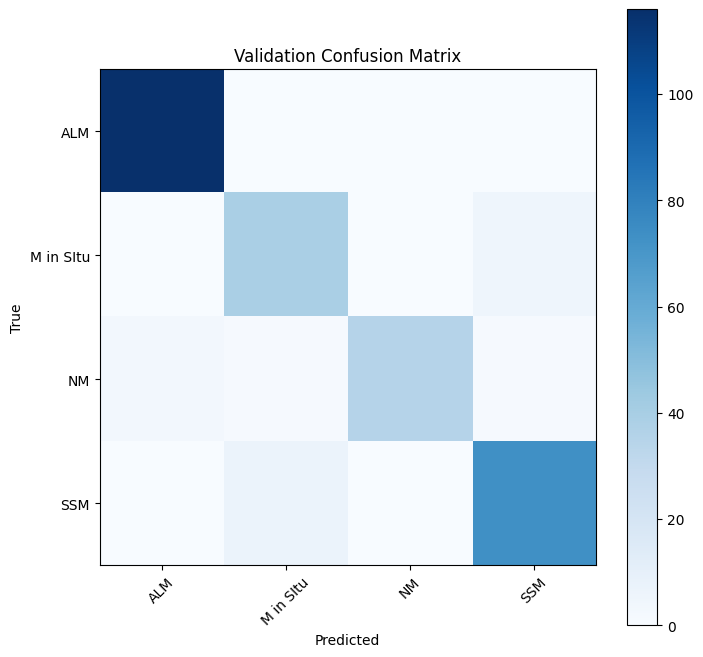

Test Classification Report:
              precision    recall  f1-score   support

         ALM       0.96      1.00      0.98        26
   M in SItu       0.90      0.79      0.84        24
          NM       1.00      0.94      0.97        18
         SSM       0.78      0.90      0.84        20

    accuracy                           0.91        88
   macro avg       0.91      0.91      0.91        88
weighted avg       0.91      0.91      0.91        88

Test Confusion Matrix:
[[26  0  0  0]
 [ 0 19  0  5]
 [ 1  0 17  0]
 [ 0  2  0 18]]


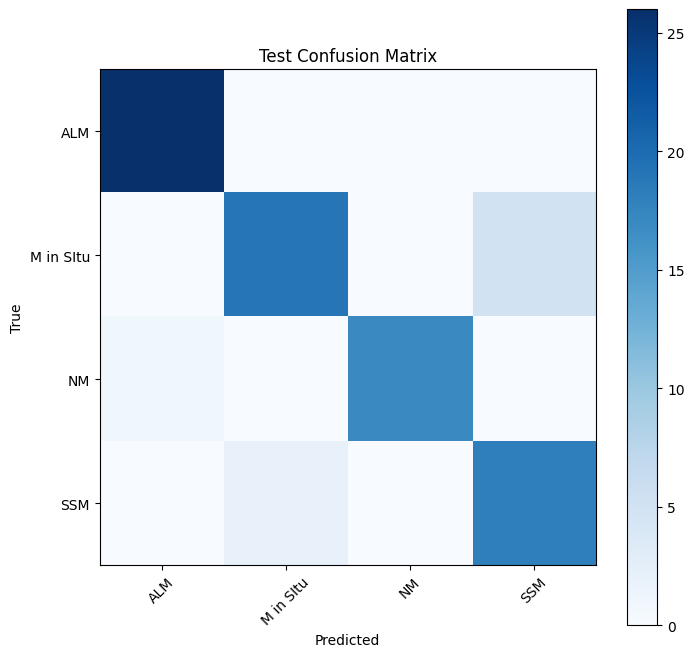

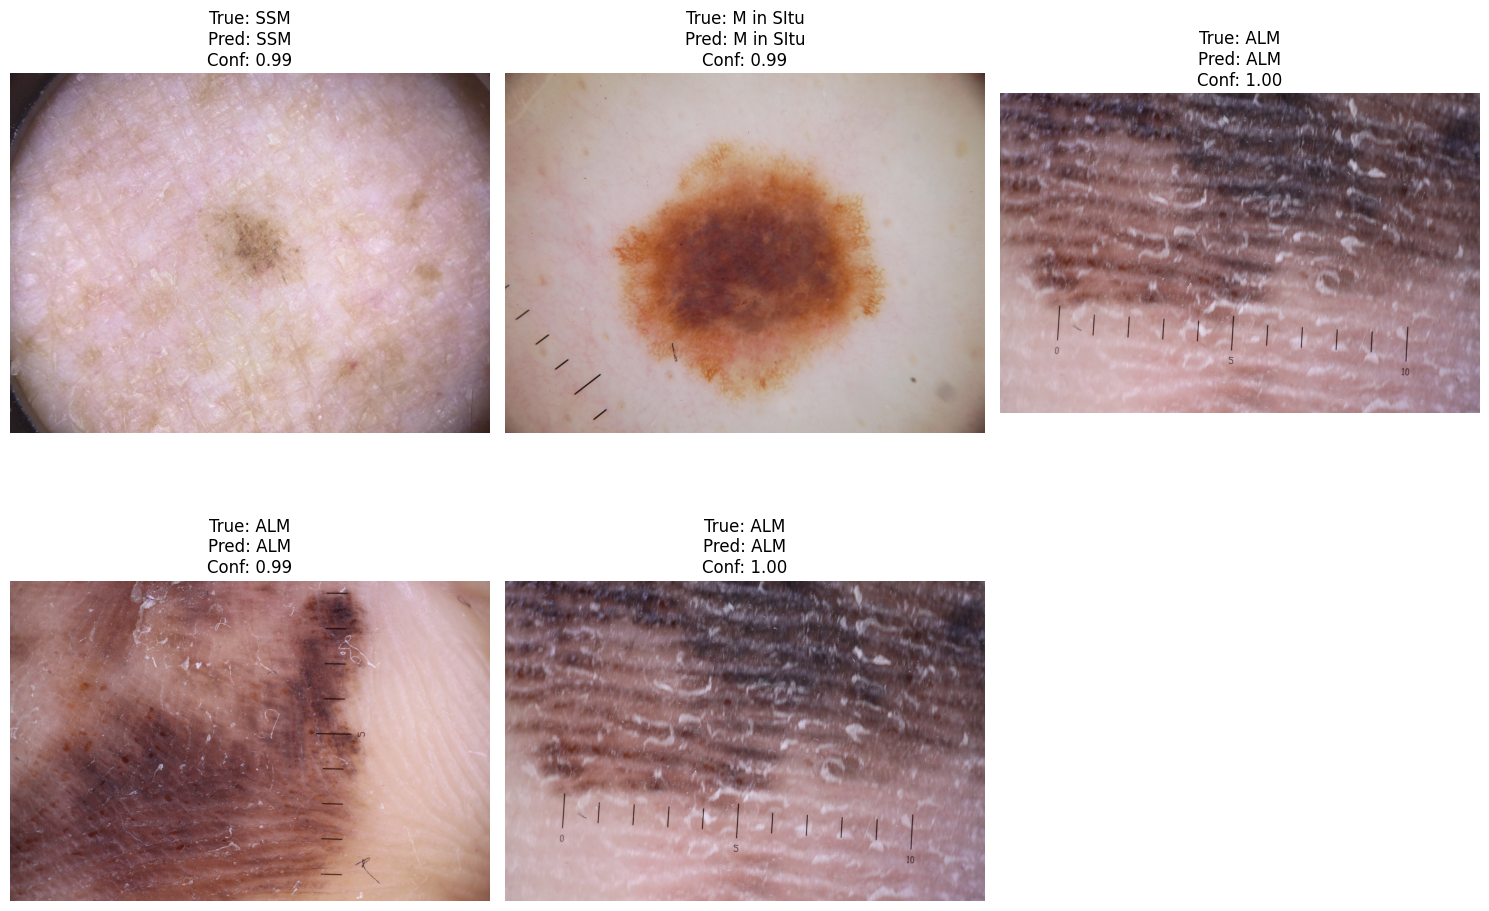

In [12]:
import torch
import torch.nn as nn
from torchvision import datasets, models, transforms
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt
import joblib
import os


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


train_dir = '/kaggle/input/train-rgb'
val_dir = '/kaggle/input/valid-rgb'
test_dir = '/kaggle/input/test-rgb'


data_transforms = transforms.Compose([
    transforms.Resize((640, 640)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])


train_dataset = datasets.ImageFolder(train_dir, transform=data_transforms)
val_dataset = datasets.ImageFolder(val_dir, transform=data_transforms)
test_dataset = datasets.ImageFolder(test_dir, transform=data_transforms)


train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=False)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)


resnet34 = models.resnet34(pretrained=True)

feature_extractor = nn.Sequential(*list(resnet34.children())[:-1]).to(device)
feature_extractor.eval()  


def extract_features(data_loader):
    features = []
    labels = []
    
    with torch.no_grad():
        for inputs, lbls in data_loader:
            inputs = inputs.to(device)
            output = feature_extractor(inputs)
            output = output.view(output.size(0), -1)  
            features.append(output.cpu().numpy())
            labels.append(lbls.numpy())
    
    return np.concatenate(features), np.concatenate(labels)


train_features, train_labels = extract_features(train_loader)
val_features, val_labels = extract_features(val_loader)
test_features, test_labels = extract_features(test_loader)


scaler = StandardScaler()
train_features = scaler.fit_transform(train_features)
val_features = scaler.transform(val_features)
test_features = scaler.transform(test_features)


svm_classifier = SVC(kernel='linear', C=1, probability=True, random_state=42)
svm_classifier.fit(train_features, train_labels)


model_save_path = 'svm_classifier_rgb1_model.pkl'
joblib.dump(svm_classifier, model_save_path)
print(f"Model saved to {model_save_path}")


val_predictions = svm_classifier.predict(val_features)
test_predictions = svm_classifier.predict(test_features)
test_pred_proba = svm_classifier.predict_proba(test_features)


print("Validation Classification Report:")
print(classification_report(val_labels, val_predictions, target_names=val_dataset.classes))

print("Validation Confusion Matrix:")
conf_mat_val = confusion_matrix(val_labels, val_predictions)
print(conf_mat_val)


plt.figure(figsize=(8, 8))
plt.imshow(conf_mat_val, cmap='Blues')
plt.colorbar()
plt.xticks(np.arange(len(val_dataset.classes)), val_dataset.classes, rotation=45)
plt.yticks(np.arange(len(val_dataset.classes)), val_dataset.classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Validation Confusion Matrix')
plt.show()


print("Test Classification Report:")
print(classification_report(test_labels, test_predictions, target_names=test_dataset.classes))

print("Test Confusion Matrix:")
conf_mat_test = confusion_matrix(test_labels, test_predictions)
print(conf_mat_test)


plt.figure(figsize=(8, 8))
plt.imshow(conf_mat_test, cmap='Blues')
plt.colorbar()
plt.xticks(np.arange(len(test_dataset.classes)), test_dataset.classes, rotation=45)
plt.yticks(np.arange(len(test_dataset.classes)), test_dataset.classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Test Confusion Matrix')
plt.show()


loaded_svm_model = joblib.load(model_save_path)
loaded_test_predictions = loaded_svm_model.predict(test_features)
loaded_test_pred_proba = loaded_svm_model.predict_proba(test_features)


predictions_df = pd.DataFrame({
    'True Label': test_labels,
    'Predicted Label': loaded_test_predictions,
    'Confidence': np.max(loaded_test_pred_proba, axis=1)
})


num_images = 5
indices = np.random.choice(len(test_dataset), num_images, replace=False)

plt.figure(figsize=(15, 15))
for i, idx in enumerate(indices):
    img_path = os.path.join(test_dir, test_dataset.samples[idx][0])
    img = plt.imread(img_path)
    
    true_label = test_dataset.classes[test_labels[idx]]
    predicted_label = test_dataset.classes[loaded_test_predictions[idx]]
    confidence = predictions_df.loc[idx, 'Confidence']
    
    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"True: {true_label}\nPred: {predicted_label}\nConf: {confidence:.2f}")

plt.tight_layout()
plt.show()
